In [1]:
%load_ext autoreload
%autoreload 2

In [2]:
import os

import numpy as np

import channel_design
from channel_design import (
    annualised_cost,
    candidate_designs,
    route_with_head_loss_iteration,
    start_map,
)

In [ ]:
#plain the model scans
# m = start_map()
# m

In [4]:
## 1. SETTINGS ##


# ---- Paths ----
PROJECT_DIR = '../elliot_main_channel'
ROUTES_DIR = os.path.join(PROJECT_DIR, '0_run1')
SEQUENTIAL_RUN_TEMPLATE = os.path.join('inputs/Sequential_Run.csv')

DEM_PATH = "inputs/DEM/merged_dem.tif"
ROCK_DEPTH_PATH = "inputs/DEM/low_res_resampled.tif"

# ---- Routing area (lon/lat): left, bottom, right, top ----
ROUTING_BOUNDS = (147, -21, 149, -19)

# ---- Channel hydraulics ----
MANNING_N = 0.03
SIDE_SLOPE = 2  # horizontal : vertical


# ---- Sequential run settings ----
MAX_RUNS = 4
RESIDUAL_HEAD_LOSS_TOL_M = 0.1

# ---- Per-section inputs ----
SECTIONS = {
    'section1': dict(
        start=(147.31, -19.81),
        finish=(147.857, -19.978),       # before pumping station
        start_elevation=36,              # DFL
        gross_diversions_m3_s=19.4,
        default_linear_cost=48227516,
        # total_loss_GL=8.7,
        approximate_length_km=67,        # used for the length penalty
        # no_cells=1991, #not used anymore
    ),
    'section2': dict(
        start=(147.866, -19.974),        # after pumping station
        finish=(148.079, -20.086),       # before Euri Creek
        start_elevation=40,              # DFL
        gross_diversions_m3_s=10,
        default_linear_cost=17772388,
        # total_loss_GL=2.9,
        approximate_length_km=40,
        # no_cells=805,#not used anymore
    ),
}
# ---- Router settings ----
# SAMPLE_F = 250
# MAX_FILL_SIPHON_ENDS = 5
# Pass the settings above to channel_design
channel_design.configure(
    ROUTES_DIR=ROUTES_DIR,
    SEQUENTIAL_RUN_TEMPLATE=SEQUENTIAL_RUN_TEMPLATE,
    DEM_PATH=DEM_PATH,
    ROCK_DEPTH_PATH=ROCK_DEPTH_PATH,
    ROUTING_BOUNDS=ROUTING_BOUNDS,
    MANNING_N=MANNING_N,
    SIDE_SLOPE=SIDE_SLOPE,
    SAMPLE_F=250,
    MAX_FILL_SIPHON_ENDS=5,
    MAX_RUNS=MAX_RUNS,
    RESIDUAL_HEAD_LOSS_TOL_M=RESIDUAL_HEAD_LOSS_TOL_M,
    CROSS_DRAINAGE_COST_FACTOR=1,
    SECTIONS=SECTIONS,
)


In [4]:
## 2. CANDIDATE DESIGNS ##

# Flow velocities (m/s) swept when generating candidate channel designs
VELOCITY_RANGES = {
    'section1': np.arange(0.490, 0.491, 0.01),
    # 'section2': np.arange(0.425, 0.444, 0.001),
    'section2': np.arange(0.437, 0.438, 0.001),
}

version = 'cost-sensitivity-analysis'
section = 'section2'

designs = candidate_designs(section, ratios=[5], velocities=VELOCITY_RANGES[section])
[design[5] for design in designs]  # velocities kept

[np.float64(0.437)]

In [ ]:
## 3. run WaterRoute for the candidate designs ##
for section, ratio, depth, width, slope_1_in_x, velocity in designs:
    run_name = f'{version}-{section}-r{ratio}-d{depth}-w{width}-S{slope_1_in_x}-v{velocity:.3f}'
    work_dir = os.path.join(ROUTES_DIR, run_name)
    if os.path.isdir(work_dir):
        print("Exists:", work_dir)
        continue
    print(work_dir)
    route_with_head_loss_iteration(number_of_runs=3, width_to_depth_ratio=ratio, water_depth=depth, bed_width=width,
                                   run_name=run_name, section=section, slope_for_channel_dimension=1 / slope_1_in_x)

In [5]:
## SENSITIVITY ANALYSIS for linear cost ##

version = 'LC-SA-v1'
section = 'section2'

# Flow velocities (m/s) swept when generating candidate channel designs
VELOCITY_RANGES = {
    'section1': np.arange(0.490, 0.491, 0.01),
    # 'section2': np.arange(0.425, 0.444, 0.001),
    'section2': np.arange(0.437, 0.438, 0.001),
}

designs = candidate_designs(section, ratios=[5], velocities=VELOCITY_RANGES[section])
[design[5] for design in designs]  # velocities kept

## sensitivity analysis for section2 linear cost ##

LINEAR_COST_FACTORS = [0.7, 1.3]

# BASE_COST_S2 = SECTIONS['section2']['default_linear_cost']              # baseline default_linear_cost for section2

for linear_cost_factor in LINEAR_COST_FACTORS:
    # print(cost_factor)
    # SECTIONS['section2']['default_linear_cost'] = SECTIONS['section2']['default_linear_cost']* cost_factor
    # SECTIONS['section2']['total_loss_GL'] = SECTIONS['section2']['total_loss_GL']* (cost_factor)  # scale the total loss by the same factor

    # Re-pass settings so channel_design uses the updated cost
    channel_design.configure(
        ROUTES_DIR=ROUTES_DIR,
        SEQUENTIAL_RUN_TEMPLATE=SEQUENTIAL_RUN_TEMPLATE,
        DEM_PATH=DEM_PATH,
        ROCK_DEPTH_PATH=ROCK_DEPTH_PATH,
        ROUTING_BOUNDS=ROUTING_BOUNDS,
        MANNING_N=MANNING_N,
        SIDE_SLOPE=SIDE_SLOPE,
        SAMPLE_F=250,
        MAX_FILL_SIPHON_ENDS=5,
        MAX_RUNS=MAX_RUNS,
        RESIDUAL_HEAD_LOSS_TOL_M=RESIDUAL_HEAD_LOSS_TOL_M,
        SECTIONS=SECTIONS,
    )

    for section, ratio, depth, width, slope_1_in_x, velocity in designs:
        run_name = (f'{version}-{section}-r{ratio}-d{depth}-w{width}'
                    f'-S{slope_1_in_x}-v{velocity:.3f}-c{int(round(linear_cost_factor * 100))}')
        work_dir = os.path.join(ROUTES_DIR, run_name)
        if os.path.isdir(work_dir):
            print("Exists:", work_dir)
            continue
        print(work_dir, "| section2 linear cost factor =", linear_cost_factor)
        route_with_head_loss_iteration(
            number_of_runs=3, width_to_depth_ratio=ratio, water_depth=depth,
            bed_width=width, run_name=run_name, section=section,
            slope_for_channel_dimension=1 / slope_1_in_x,
            linear_cost_factor=linear_cost_factor)

    # Section defaults remain unchanged; the factor applies only to this route.



../elliot_main_channel\0_run1\LC-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-c70 | section2 linear cost factor = 0.7
Linear cost: 17772388 x 0.7 = 12440671.6
Calculated channel dimensions: slope = -0.000116795141322121, mannings_n = 0.03, side_slope = 2, ratio_width_depth = 5, water depth = 1.81 m, bed width = 9.04 m
Earthwork cost weight: 1.0
approximated length (km) = 40
linear cost per km = 28923.200892691755
iteration number: 1
Earthwork cost weight: 1.0
approximated length (km) = 40
linear cost per km = 28923.200892691755
length_penalty ($/m)= 28.923200892691757
iteration number: 2
Earthwork cost weight: 1.0
approximated length (km) = 40
linear cost per km = 28923.200892691755
length_penalty ($/m)= 28.923200892691757
iteration number: 3
Earthwork cost weight: 1.0
approximated length (km) = 40
linear cost per km = 28923.200892691755
length_penalty ($/m)= 28.923200892691757
iteration number: 4
Earthwork cost weight: 1.0
approximated length (km) = 40
linear cost per km = 28923.2008926

c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'LC-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-c70_40' adjusted to 'LC_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_c70_40' for XML validity.
  ogr_write(


length of 40 is 30.78km. Cost is (2020 AUD) M$8.51
0


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'LC-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-c70_40_cross_drainage' adjusted to 'LC_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_c70_40_cross_drainage' for XML validity.
  ogr_write(
c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'LC-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-c70_40_cross_drainage_catchment' adjusted to 'LC_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_c70_40_cross_drainage_catchment' for XML validity.
  ogr_write(


AttributeError: 'Channel_Route' object has no attribute 'access_road_direct_cost_per_k'

In [5]:
## SENSITIVITY ANALYSIS for earthwork cost ##

version = 'earthwork-SA-v1'
section = 'section2'

# Flow velocities (m/s) swept when generating candidate channel designs
VELOCITY_RANGES = {
    'section1': np.arange(0.490, 0.491, 0.01),
    # 'section2': np.arange(0.425, 0.444, 0.001),
    'section2': np.arange(0.437, 0.438, 0.001),
}

designs = candidate_designs(section, ratios=[5], velocities=VELOCITY_RANGES[section])
[design[5] for design in designs]  # velocities kept

## sensitivity analysis for section2 linear cost ##

weighting_coeffeicients = [0.7, 1.3]         #70%, 100%, 130%

# BASE_COST_S2 = SECTIONS['section2']['default_linear_cost']              # baseline default_linear_cost for section2

for earthwork_cost_weight in weighting_coeffeicients:
    
    # Re-pass settings so channel_design uses the earthwork_cost_weight
    channel_design.configure(
        ROUTES_DIR=ROUTES_DIR,
        SEQUENTIAL_RUN_TEMPLATE=SEQUENTIAL_RUN_TEMPLATE,
        DEM_PATH=DEM_PATH,
        ROCK_DEPTH_PATH=ROCK_DEPTH_PATH,
        ROUTING_BOUNDS=ROUTING_BOUNDS,
        MANNING_N=MANNING_N,
        SIDE_SLOPE=SIDE_SLOPE,
        SAMPLE_F=250,
        MAX_FILL_SIPHON_ENDS=5,
        MAX_RUNS=MAX_RUNS,
        RESIDUAL_HEAD_LOSS_TOL_M=RESIDUAL_HEAD_LOSS_TOL_M,
        SECTIONS=SECTIONS,
    )

    for section, ratio, depth, width, slope_1_in_x, velocity in designs:
        run_name = (f'{version}-{section}-r{ratio}-d{depth}-w{width}'
                    f'-S{slope_1_in_x}-v{velocity:.3f}-EW{int(round(earthwork_cost_weight * 100))}')
        work_dir = os.path.join(ROUTES_DIR, run_name)
        if os.path.isdir(work_dir):
            print("Exists:", work_dir)
            continue
        print(work_dir, "| section2 earthwork scaled by  =",earthwork_cost_weight)
        route_with_head_loss_iteration(
            number_of_runs=3, width_to_depth_ratio=ratio, water_depth=depth,
            bed_width=width, run_name=run_name, section=section,
            slope_for_channel_dimension=1 / slope_1_in_x, earthwork_cost_weight = earthwork_cost_weight)

# Put the baseline cost back so later cells aren't affected

channel_design.configure(SECTIONS=SECTIONS) if False else None  

Exists: ../elliot_main_channel\0_run1\earthwork-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-EW70
Exists: ../elliot_main_channel\0_run1\earthwork-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-EW130


In [ ]:
## SENSITIVITY ANALYSIS for canal side slope ##

version = 'SS-SA-v1'
section = 'section2'

# Flow velocities (m/s) swept when generating candidate channel designs
VELOCITY_RANGES = {
    'section1': np.arange(0.490, 0.491, 0.01),
    'section2': np.arange(0.425, 0.444, 0.005),
    # 'section2': np.arange(0.437, 0.438, 0.001),
}



## sensitivity analysis for section2 linear cost ##

side_slopes = [1.5/1, 2, 2.5/1]         #70%, 100%, 130%

# BASE_COST_S2 = SECTIONS['section2']['default_linear_cost']              # baseline default_linear_cost for section2

for side_slope in side_slopes:
    
    # Re-pass settings so channel_design uses the earthwork_cost_weight
    channel_design.configure(
        ROUTES_DIR=ROUTES_DIR,
        SEQUENTIAL_RUN_TEMPLATE=SEQUENTIAL_RUN_TEMPLATE,
        DEM_PATH=DEM_PATH,
        ROCK_DEPTH_PATH=ROCK_DEPTH_PATH,
        ROUTING_BOUNDS=ROUTING_BOUNDS,
        MANNING_N=MANNING_N,
        SIDE_SLOPE=side_slope,
        SAMPLE_F=250,
        MAX_FILL_SIPHON_ENDS=5,
        MAX_RUNS=MAX_RUNS,
        RESIDUAL_HEAD_LOSS_TOL_M=RESIDUAL_HEAD_LOSS_TOL_M,
        SECTIONS=SECTIONS,
    )

    designs = candidate_designs(section, ratios=[5], velocities=VELOCITY_RANGES[section], z=side_slope)
    [design[5] for design in designs]  # velocities kept

    for section, ratio, depth, width, slope_1_in_x, velocity in designs:
        run_name = (f'{version}-{section}-r{ratio}-d{depth}-w{width}'
                    f'-S{slope_1_in_x}-v{velocity:.3f}-SS{float(round(side_slope, 2))}')
        work_dir = os.path.join(ROUTES_DIR, run_name)
        if os.path.isdir(work_dir):
            print("Exists:", work_dir)
            continue
        print(work_dir, "| section2 SS  =",side_slope)
        route_with_head_loss_iteration(
            number_of_runs=3, width_to_depth_ratio=ratio, water_depth=depth,
            bed_width=width, run_name=run_name, section=section,
            slope_for_channel_dimension=1 / slope_1_in_x, earthwork_cost_weight = 1)

# Put the baseline cost back so later cells aren't affected

channel_design.configure(SECTIONS=SECTIONS) if False else None  

../elliot_main_channel\0_run1\SS-SA-v1-section2-r5-d1.88-w9.38-S9259-v0.437-SS1.5 | section2 SS  = 1.5
17772388
Calculated channel dimensions: slope = -0.00010800302408467438, ratio_width_depth = 5, water depth = 1.88 m, bed width = 9.38 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41257.84422098822
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41257.84422098822
length_penalty ($/m)= 41.25784422098822
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41257.84422098822
length_penalty ($/m)= 41.25784422098822
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41257.84422098822
length_penalty ($/m)= 41.25784422098822
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41257.84422098822
length_penalty ($/m)= 41.25784422098822


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'SS-SA-v1-section2-r5-d1.88-w9.38-S9259-v0.437-SS1.5_40' adjusted to 'SS_SA_v1_section2_r5_d1.88_w9.38_S9259_v0.437_SS1.5_40' for XML validity.
  ogr_write(


length of 40 is 30.62km. Cost is (2020 AUD) M$8.41
0


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'SS-SA-v1-section2-r5-d1.88-w9.38-S9259-v0.437-SS1.5_40_cross_drainage' adjusted to 'SS_SA_v1_section2_r5_d1.88_w9.38_S9259_v0.437_SS1.5_40_cross_drainage' for XML validity.
  ogr_write(
c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'SS-SA-v1-section2-r5-d1.88-w9.38-S9259-v0.437-SS1.5_40_cross_drainage_catchment' adjusted to 'SS_SA_v1_section2_r5_d1.88_w9.38_S9259_v0.437_SS1.5_40_cross_drainage_catchment' for XML validity.
  ogr_write(


17772388
Calculated channel dimensions: slope = -0.00010800302408467438, ratio_width_depth = 5, water depth = 2.10 m, bed width = 10.48 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41292.52976850789
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41292.52976850789
length_penalty ($/m)= 41.29252976850789
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41292.52976850789
length_penalty ($/m)= 41.29252976850789
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41292.52976850789
length_penalty ($/m)= 41.29252976850789
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41292.52976850789
length_penalty ($/m)= 41.29252976850789


...

17772388
Calculated channel dimensions: slope = -0.00012610340479192938, ratio_width_depth = 5, water depth = 1.97 m, bed width = 9.83 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41271.43515238242
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41271.43515238242
length_penalty ($/m)= 41.27143515238242
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41271.43515238242
length_penalty ($/m)= 41.27143515238242
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41271.43515238242
length_penalty ($/m)= 41.27143515238242
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41271.43515238242
length_penalty ($/m)= 41.27143515238242


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'SS-SA-v1-section2-r5-d1.75-w8.73-S7930-v0.437-SS2.5_40' adjusted to 'SS_SA_v1_section2_r5_d1.75_w8.73_S7930_v0.437_SS2.5_40' for XML validity.
  ogr_write(


length of 40 is 30.56km. Cost is (2020 AUD) M$8.63
0


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'SS-SA-v1-section2-r5-d1.75-w8.73-S7930-v0.437-SS2.5_40_cross_drainage' adjusted to 'SS_SA_v1_section2_r5_d1.75_w8.73_S7930_v0.437_SS2.5_40_cross_drainage' for XML validity.
  ogr_write(
c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'SS-SA-v1-section2-r5-d1.75-w8.73-S7930-v0.437-SS2.5_40_cross_drainage_catchment' adjusted to 'SS_SA_v1_section2_r5_d1.75_w8.73_S7930_v0.437_SS2.5_40_cross_drainage_catchment' for XML validity.
  ogr_write(


No need for run 3 as the residual head loss is less than 0.1 m.


In [6]:
## SENSITIVITY ANALYSIS for cross-drainage structure ##

version = 'CD-SA-v1'
section = 'section2'

# Flow velocities (m/s) swept when generating candidate channel designs
VELOCITY_RANGES = {
    'section1': np.arange(0.490, 0.491, 0.01),
    # 'section2': np.arange(0.425, 0.444, 0.001),
    'section2': np.arange(0.437, 0.438, 0.001),
}

designs = candidate_designs(section, ratios=[5], velocities=VELOCITY_RANGES[section])
[design[5] for design in designs]  # velocities kept

## sensitivity analysis for section2 linear cost ##

CD_cost_factors = [0.5, 1.5]         #70%, 100%, 130%

# BASE_COST_S2 = SECTIONS['section2']['default_linear_cost']              # baseline default_linear_cost for section2

for cross_drainage_cost_factor in CD_cost_factors:
    
    # Re-pass settings so channel_design uses the earthwork_cost_weight
    channel_design.configure(
        ROUTES_DIR=ROUTES_DIR,
        SEQUENTIAL_RUN_TEMPLATE=SEQUENTIAL_RUN_TEMPLATE,
        DEM_PATH=DEM_PATH,
        ROCK_DEPTH_PATH=ROCK_DEPTH_PATH,
        ROUTING_BOUNDS=ROUTING_BOUNDS,
        MANNING_N=MANNING_N,
        SIDE_SLOPE=2,
        SAMPLE_F=250,
        MAX_FILL_SIPHON_ENDS=5,
        MAX_RUNS=MAX_RUNS,
        RESIDUAL_HEAD_LOSS_TOL_M=RESIDUAL_HEAD_LOSS_TOL_M,
        CROSS_DRAINAGE_COST_FACTOR = cross_drainage_cost_factor,
        SECTIONS=SECTIONS,
    )

    for section, ratio, depth, width, slope_1_in_x, velocity in designs:
        run_name = (f'{version}-{section}-r{ratio}-d{depth}-w{width}'
                    f'-S{slope_1_in_x}-v{velocity:.3f}-CD{float(round(cross_drainage_cost_factor, 2))}')
        work_dir = os.path.join(ROUTES_DIR, run_name)
        if os.path.isdir(work_dir):
            print("Exists:", work_dir)
            continue
        print(work_dir, "| section2 CD  =",cross_drainage_cost_factor)
        route_with_head_loss_iteration(
            number_of_runs=3, width_to_depth_ratio=ratio, water_depth=depth,
            bed_width=width, run_name=run_name, section=section,
            slope_for_channel_dimension=1 / slope_1_in_x, earthwork_cost_weight = 1)

# Put the baseline cost back so later cells aren't affected

channel_design.configure(SECTIONS=SECTIONS) if False else None  

../elliot_main_channel\0_run1\CD-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-CD0.5 | section2 CD  = 0.5
17772388
Calculated channel dimensions: slope = -0.000116795141322121, ratio_width_depth = 5, water depth = 1.81 m, bed width = 9.04 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
length_penalty ($/m)= 41.24744329598822
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
length_penalty ($/m)= 41.24744329598822
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
length_penalty ($/m)= 41.24744329598822
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
length_penalty ($/m)= 41.24744329598822


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'CD-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-CD0.5_40' adjusted to 'CD_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_CD0.5_40' for XML validity.
  ogr_write(


length of 40 is 30.82km. Cost is (2020 AUD) M$8.45
0


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'CD-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-CD0.5_40_cross_drainage' adjusted to 'CD_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_CD0.5_40_cross_drainage' for XML validity.
  ogr_write(
c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'CD-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-CD0.5_40_cross_drainage_catchment' adjusted to 'CD_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_CD0.5_40_cross_drainage_catchment' for XML validity.
  ogr_write(


17772388
Calculated channel dimensions: slope = -0.000116795141322121, ratio_width_depth = 5, water depth = 2.01 m, bed width = 10.03 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
length_penalty ($/m)= 41.27805125686945
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
length_penalty ($/m)= 41.27805125686945
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
length_penalty ($/m)= 41.27805125686945
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
length_penalty ($/m)= 41.27805125686945


...

17772388
Calculated channel dimensions: slope = -0.000116795141322121, ratio_width_depth = 5, water depth = 2.01 m, bed width = 10.03 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
length_penalty ($/m)= 41.27805125686945
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
length_penalty ($/m)= 41.27805125686945
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
length_penalty ($/m)= 41.27805125686945
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41278.051256869454
length_penalty ($/m)= 41.27805125686945


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'CD-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-CD1.5_40' adjusted to 'CD_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_CD1.5_40' for XML validity.
  ogr_write(


length of 40 is 30.42km. Cost is (2020 AUD) M$8.70
0


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'CD-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-CD1.5_40_cross_drainage' adjusted to 'CD_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_CD1.5_40_cross_drainage' for XML validity.
  ogr_write(
c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'CD-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-CD1.5_40_cross_drainage_catchment' adjusted to 'CD_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_CD1.5_40_cross_drainage_catchment' for XML validity.
  ogr_write(


No need for run 3 as the residual head loss is less than 0.1 m.


In [22]:
## SENSITIVITY ANALYSIS for mannings n  ##

version = 'MN-SA-v1'
section = 'section2'

# Flow velocities (m/s) swept when generating candidate channel designs
VELOCITY_RANGES = {
    'section1': np.arange(0.490, 0.491, 0.01),
    # 'section2': np.arange(0.425, 0.444, 0.001),
    'section2': np.arange(0.437, 0.438, 0.001),
}


## sensitivity analysis for section2 linear cost ##

MANNING_N = [0.28, 0.34]         #70%, 100%, 130%

# BASE_COST_S2 = SECTIONS['section2']['default_linear_cost']              # baseline default_linear_cost for section2

for manning_n in MANNING_N:
    
    # Re-pass settings so channel_design uses the earthwork_cost_weight
    channel_design.configure(
        ROUTES_DIR=ROUTES_DIR,
        SEQUENTIAL_RUN_TEMPLATE=SEQUENTIAL_RUN_TEMPLATE,
        DEM_PATH=DEM_PATH,
        ROCK_DEPTH_PATH=ROCK_DEPTH_PATH,
        ROUTING_BOUNDS=ROUTING_BOUNDS,
        MANNING_N=manning_n,
        SIDE_SLOPE=2,
        SAMPLE_F=250,
        MAX_FILL_SIPHON_ENDS=5,
        MAX_RUNS=MAX_RUNS,
        RESIDUAL_HEAD_LOSS_TOL_M=RESIDUAL_HEAD_LOSS_TOL_M,
        CROSS_DRAINAGE_COST_FACTOR = 1,
        SECTIONS=SECTIONS,
    )

    designs = candidate_designs(section, ratios=[5], velocities=VELOCITY_RANGES[section], manning_n=manning_n)
    print([design[5] for design in designs])  # velocities kept

    for section, ratio, depth, width, slope_1_in_x, velocity in designs:
        run_name = (f'{version}-{section}-r{ratio}-d{depth}-w{width}'
                    f'-S{slope_1_in_x}-v{velocity:.3f}-ME{float(round(manning_n, 2))}')
        work_dir = os.path.join(ROUTES_DIR, run_name)
        if os.path.isdir(work_dir):
            print("Exists:", work_dir)
            continue
        print(work_dir, "| section2 manning n   =", manning_n)
        route_with_head_loss_iteration(
            number_of_runs=3, width_to_depth_ratio=ratio, water_depth=depth,
            bed_width=width, run_name=run_name, section=section,
            slope_for_channel_dimension=1 / slope_1_in_x, earthwork_cost_weight = 1)

# Put the baseline cost back so later cells aren't affected

channel_design.configure(SECTIONS=SECTIONS) if False else None  

[np.float64(0.437)]
../elliot_main_channel\0_run1\MN-SA-v1-section2-r5-d1.81-w9.04-S98-v0.437-ME0.28 | section2 manning n   = 0.28
17772388
Calculated channel dimensions: slope = -0.01020408163265306, mannings_n = 0.28, side_slope = 2, ratio_width_depth = 5, water depth = 1.81 m, bed width = 9.04 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
length_penalty ($/m)= 41.24744329598822
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
length_penalty ($/m)= 41.24744329598822
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
length_penalty ($/m)= 41.24744329598822
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41247.44329598822
length_penalty ($/m)= 41.24744

c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'MN-SA-v1-section2-r5-d1.81-w9.04-S98-v0.437-ME0.28_40' adjusted to 'MN_SA_v1_section2_r5_d1.81_w9.04_S98_v0.437_ME0.28_40' for XML validity.
  ogr_write(


length of 40 is 29.50km. Cost is (2020 AUD) M$571.08
0


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'MN-SA-v1-section2-r5-d1.81-w9.04-S98-v0.437-ME0.28_40_cross_drainage' adjusted to 'MN_SA_v1_section2_r5_d1.81_w9.04_S98_v0.437_ME0.28_40_cross_drainage' for XML validity.
  ogr_write(
c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'MN-SA-v1-section2-r5-d1.81-w9.04-S98-v0.437-ME0.28_40_cross_drainage_catchment' adjusted to 'MN_SA_v1_section2_r5_d1.81_w9.04_S98_v0.437_ME0.28_40_cross_drainage_catchment' for XML validity.
  ogr_write(


0.28 delete
17772388
Calculated channel dimensions: slope = -0.01020408163265306, mannings_n = 0.28, side_slope = 2, ratio_width_depth = 5, water depth = 1.85 m, bed width = 9.24 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2735336233
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2735336233
length_penalty ($/m)= 41.2532735336233
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2735336233
length_penalty ($/m)= 41.2532735336233
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2735336233
length_penalty ($/m)= 41.2532735336233
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2735336233
length_penalty ($/m)= 41.2532735336233


...

0.34 delete
17772388
Calculated channel dimensions: slope = -0.014925373134328358, mannings_n = 0.34, side_slope = 2, ratio_width_depth = 5, water depth = 1.85 m, bed width = 9.24 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2189309667
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2189309667
length_penalty ($/m)= 41.2532189309667
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2189309667
length_penalty ($/m)= 41.2532189309667
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2189309667
length_penalty ($/m)= 41.2532189309667
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 41253.2189309667
length_penalty ($/m)= 41.2532189309667


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'MN-SA-v1-section2-r5-d1.81-w9.04-S67-v0.437-ME0.34_40' adjusted to 'MN_SA_v1_section2_r5_d1.81_w9.04_S67_v0.437_ME0.34_40' for XML validity.
  ogr_write(


length of 40 is 29.77km. Cost is (2020 AUD) M$590.25
0


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'MN-SA-v1-section2-r5-d1.81-w9.04-S67-v0.437-ME0.34_40_cross_drainage' adjusted to 'MN_SA_v1_section2_r5_d1.81_w9.04_S67_v0.437_ME0.34_40_cross_drainage' for XML validity.
  ogr_write(
c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'MN-SA-v1-section2-r5-d1.81-w9.04-S67-v0.437-ME0.34_40_cross_drainage_catchment' adjusted to 'MN_SA_v1_section2_r5_d1.81_w9.04_S67_v0.437_ME0.34_40_cross_drainage_catchment' for XML validity.
  ogr_write(


No need for run 4 as the residual head loss is less than 0.1 m.


In [8]:
version = 'MN-SA-v1'
section = 'section2'

# Flow velocities (m/s) swept when generating candidate channel designs
VELOCITY_RANGES = {
    'section1': np.arange(0.490, 0.491, 0.01),
    # 'section2': np.arange(0.425, 0.444, 0.001),
    'section2': np.arange(0.437, 0.438, 0.001),
}




[(n, candidate_designs('section2', ratios=[5], velocities=VELOCITY_RANGES[section], manning_n=n, z=2)) for n in (0.18, 0.28, 0.34)]

[(0.18,
  [('section2',
    5,
    np.float64(1.81),
    np.float64(9.04),
    238,
    np.float64(0.437))]),
 (0.28,
  [('section2',
    5,
    np.float64(1.81),
    np.float64(9.04),
    98,
    np.float64(0.437))]),
 (0.34,
  [('section2',
    5,
    np.float64(1.81),
    np.float64(9.04),
    67,
    np.float64(0.437))])]

In [23]:
## SENSITIVITY ANALYSIS for discount rate  ##

version = 'DR-SA-v1'
section = 'section2'

# Flow velocities (m/s) swept when generating candidate channel designs
VELOCITY_RANGES = {
    'section1': np.arange(0.490, 0.491, 0.01),
    # 'section2': np.arange(0.425, 0.444, 0.001),
    'section2': np.arange(0.437, 0.438, 0.001),
}


## Discount-rate scenarios ##

DISCOUNT_RATES = [0.03, 0.07, 0.1]
MANNING_N = 0.03
SIDE_SLOPE = 2

designs = candidate_designs(
    section,
    ratios=[5],
    velocities=VELOCITY_RANGES[section],
    manning_n=MANNING_N,
    z=SIDE_SLOPE,
)

for discount_rate in DISCOUNT_RATES:
    channel_design.configure(
        ROUTES_DIR=ROUTES_DIR,
        SEQUENTIAL_RUN_TEMPLATE=SEQUENTIAL_RUN_TEMPLATE,
        DEM_PATH=DEM_PATH,
        ROCK_DEPTH_PATH=ROCK_DEPTH_PATH,
        ROUTING_BOUNDS=ROUTING_BOUNDS,
        MANNING_N=MANNING_N,
        SIDE_SLOPE=SIDE_SLOPE,
        SAMPLE_F=250,
        MAX_FILL_SIPHON_ENDS=5,
        MAX_RUNS=MAX_RUNS,
        RESIDUAL_HEAD_LOSS_TOL_M=RESIDUAL_HEAD_LOSS_TOL_M,
        CROSS_DRAINAGE_COST_FACTOR=1,
        DISCOUNT_RATE=discount_rate,
        SECTIONS=SECTIONS,
    )

    for section, ratio, depth, width, slope_1_in_x, velocity in designs:
        run_name = (f'{version}-{section}-r{ratio}-d{depth}-w{width}'
                    f'-S{slope_1_in_x}-v{velocity:.3f}-DR{discount_rate:.3f}')
        work_dir = os.path.join(ROUTES_DIR, run_name)
        if os.path.isdir(work_dir):
            print("Exists:", work_dir)
            continue
        print(work_dir, "| discount rate =", discount_rate)
        route_with_head_loss_iteration(
            number_of_runs=3, width_to_depth_ratio=ratio, water_depth=depth,
            bed_width=width, run_name=run_name, section=section,
            slope_for_channel_dimension=1 / slope_1_in_x, earthwork_cost_weight = 1)

    print(f"Finished discount-rate scenario: {discount_rate:.1%}")

../elliot_main_channel\0_run1\DR-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-DR0.030 | discount rate = 0.03
17772388
Calculated channel dimensions: slope = -0.000116795141322121, mannings_n = 0.03, side_slope = 2, ratio_width_depth = 5, water depth = 1.81 m, bed width = 9.04 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26321.145460732503
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26321.145460732503
length_penalty ($/m)= 26.321145460732502
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26321.145460732503
length_penalty ($/m)= 26.321145460732502
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26321.145460732503
length_penalty ($/m)= 26.321145460732502
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26321.145460732503
length_penalty ($/m)= 26.321145460732502


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'DR-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-DR0.030_40' adjusted to 'DR_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_DR0.030_40' for XML validity.
  ogr_write(


length of 40 is 30.85km. Cost is (2020 AUD) M$5.38
0


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'DR-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-DR0.030_40_cross_drainage' adjusted to 'DR_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_DR0.030_40_cross_drainage' for XML validity.
  ogr_write(
c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'DR-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-DR0.030_40_cross_drainage_catchment' adjusted to 'DR_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_DR0.030_40_cross_drainage_catchment' for XML validity.
  ogr_write(


Discount rate = 3.0%; annualised cost per saleable ML = $67.09
0.03 delete
17772388
Calculated channel dimensions: slope = -0.000116795141322121, mannings_n = 0.03, side_slope = 2, ratio_width_depth = 5, water depth = 2.01 m, bed width = 10.03 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26351.593835220316
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26351.593835220316
length_penalty ($/m)= 26.351593835220317
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26351.593835220316
length_penalty ($/m)= 26.351593835220317
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26351.593835220316
length_penalty ($/m)= 26.351593835220317
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 26351.593835220316
length_penalty ($/m)= 26.351593835220317


...

Discount rate = 10.0%; annualised cost per saleable ML = $144.67
0.03 delete
17772388
Calculated channel dimensions: slope = -0.000116795141322121, mannings_n = 0.03, side_slope = 2, ratio_width_depth = 5, water depth = 2.01 m, bed width = 10.03 m
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 53895.98702233621
iteration number: 1
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 53895.98702233621
length_penalty ($/m)= 53.89598702233621
iteration number: 2
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 53895.98702233621
length_penalty ($/m)= 53.89598702233621
iteration number: 3
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 53895.98702233621
length_penalty ($/m)= 53.89598702233621
iteration number: 4
Earthwork cost weight: 1
approximated length (km) = 40
linear cost per km = 53895.98702233621
length_penalty ($/m)= 53.89598702233621


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'DR-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-DR0.100_40' adjusted to 'DR_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_DR0.100_40' for XML validity.
  ogr_write(


length of 40 is 30.42km. Cost is (2020 AUD) M$11.37
0


c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'DR-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-DR0.100_40_cross_drainage' adjusted to 'DR_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_DR0.100_40_cross_drainage' for XML validity.
  ogr_write(
c:\Users\seo010\miniforge3\envs\channelroute\Lib\site-packages\pyogrio\raw.py:733: RuntimeWarning: Layer name 'DR-SA-v1-section2-r5-d1.81-w9.04-S8562-v0.437-DR0.100_40_cross_drainage_catchment' adjusted to 'DR_SA_v1_section2_r5_d1.81_w9.04_S8562_v0.437_DR0.100_40_cross_drainage_catchment' for XML validity.
  ogr_write(


Discount rate = 10.0%; annualised cost per saleable ML = $151.86
No need for run 3 as the residual head loss is less than 0.1 m.
Finished discount-rate scenario: 10.0%


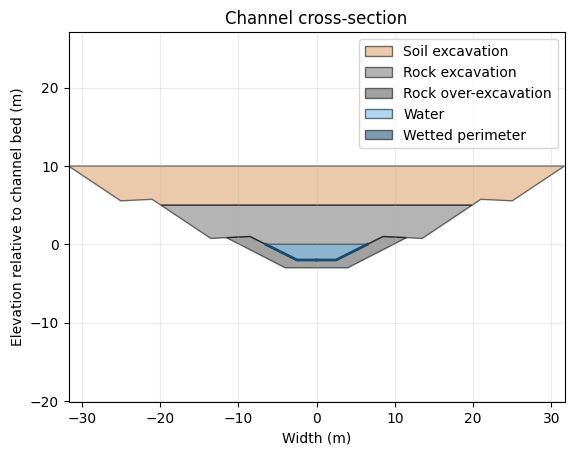

In [36]:
import matplotlib.pyplot as plt
from waterroute.channel.earthworks import plot_channel_geometry

plot_channel_geometry(DFLwrtNS= -10, bedWidth=5, depthFlow=2, freeboard=1, sides=2)
plt.show()